# Title

Detection and Characterisation of Subsurface Ice in Lunar South Polar Regions using Chandrayaan-2 DFSAR Data. 

# Objective 

Analyze Chandrayaan-2 DFSAR radar observations to identify strong subsurface radar reflections that may indicate potential ice-bearing regions for future landing site and rover traverse planning.

# methodology

1. Data Loading
2. Signal Analysis
3. Histogram Analysis
4. Signal Normalization
5. Ice Probability Scoring
6. Peak Detection
7. Candidate Region Identification

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

file_path = "CH2O_09337_DFRS_DS95_2021_272_00_57/calibrated/ch2o_frs_calibrated_01_21272001904.csv"

df = pd.read_csv(file_path, header=None)

df.columns = [
    "Day",
    "Time",
    "Frequency",
    "Value_1",
    "Value_2",
    "Signal"
]

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878


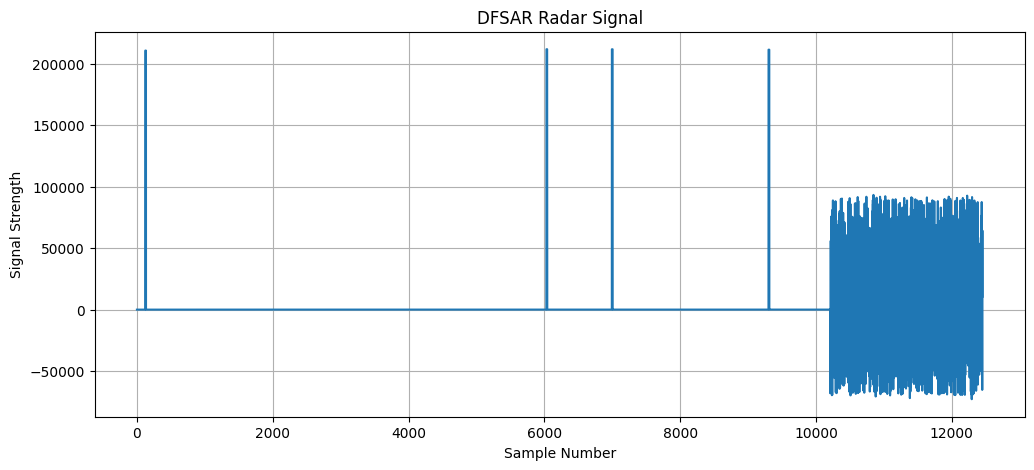

In [3]:
plt.figure(figsize=(12,5))

plt.plot(df["Signal"])

plt.title("DFSAR Radar Signal")
plt.xlabel("Sample Number")
plt.ylabel("Signal Strength")

plt.grid(True)

plt.show()

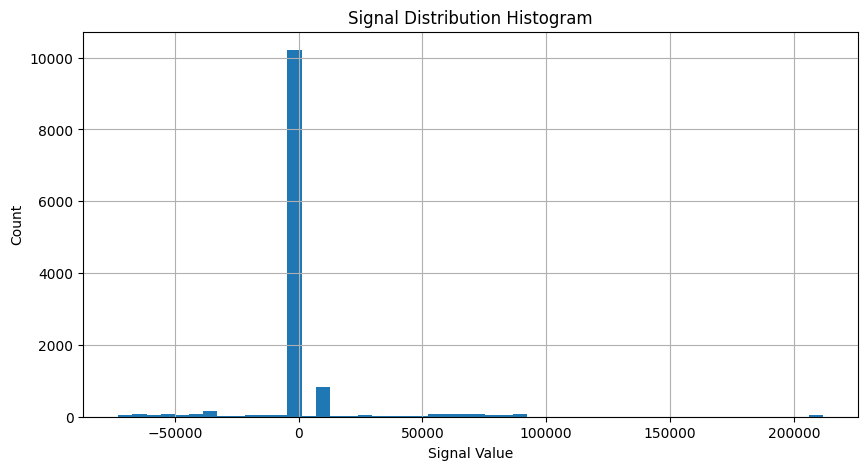

In [4]:
plt.figure(figsize=(10,5))

plt.hist(df["Signal"], bins=50)

plt.title("Signal Distribution Histogram")
plt.xlabel("Signal Value")
plt.ylabel("Count")

plt.grid(True)

plt.show()

In [5]:
signal_min = df["Signal"].min()
signal_max = df["Signal"].max()

df["Normalized_Signal"] = (
    (df["Signal"] - signal_min)
    / (signal_max - signal_min)
)

df["Ice_Probability"] = (
    df["Normalized_Signal"] * 100
)

top_ice = df.sort_values(
    "Ice_Probability",
    ascending=False
)

top_ice[
    ["Time", "Signal", "Ice_Probability"]
].head(20)

,Time,Signal,Ice_Probability
6030,1637.977588,211780.448691,100.000000
6031,1638.059508,211780.443540,99.999998
6032,1638.141428,211780.438323,99.999996
6033,1638.223348,211780.433040,99.999995
6034,1638.305268,211780.427693,99.999993
6035,1638.387188,211780.422280,99.999991
6036,1638.469108,211780.416803,99.999989
6037,1638.551028,211780.411261,99.999987
6038,1638.632948,211780.405653,99.999985
6039,1638.714868,211780.399981,99.999983


In [6]:
threshold = df["Signal"].quantile(0.95)

ice_candidates = df[
    df["Signal"] >= threshold
]

print("Threshold:", threshold)
print("Number of Candidates:", len(ice_candidates))

ice_candidates.head(20)

Threshold: 27398.325172999997
Number of Candidates: 623


,Day,Time,Frequency,Value_1,Value_2,Signal,Normalized_Signal,Ice_Probability
122,2021-272,1153.994240,2.240000e+09,2.240200e+09,2.239989e+09,210683.615156,0.996146,99.614643
123,2021-272,1154.076160,2.240000e+09,2.240200e+09,2.239989e+09,210684.007046,0.996148,99.614781
124,2021-272,1154.158080,2.240000e+09,2.240200e+09,2.239989e+09,210684.384929,0.996149,99.614914
125,2021-272,1154.240000,2.240000e+09,2.240200e+09,2.239989e+09,210684.754993,0.996150,99.615044
126,2021-272,1154.321920,2.240000e+09,2.240200e+09,2.239989e+09,210685.093604,0.996152,99.615163
127,2021-272,1154.403840,2.240000e+09,2.240200e+09,2.239989e+09,210685.498058,0.996153,99.615305
128,2021-272,1154.485760,2.240000e+09,2.240200e+09,2.239989e+09,210685.851332,0.996154,99.615429
129,2021-272,1154.567680,2.240000e+09,2.240200e+09,2.239989e+09,210686.226171,0.996156,99.615561
130,2021-272,1154.649600,2.240000e+09,2.240200e+09,2.239989e+09,210686.597672,0.996157,99.615691
131,2021-272,1154.731520,2.240000e+09,2.240200e+09,2.239989e+09,210686.958755,0.996158,99.615818


In [7]:
threshold = df["Signal"].quantile(0.95)

ice_candidates = df[
    df["Signal"] >= threshold
]

print("Threshold:", threshold)
print("Number of Candidates:", len(ice_candidates))

ice_candidates.head(20)

Threshold: 27398.325172999997
Number of Candidates: 623


,Day,Time,Frequency,Value_1,Value_2,Signal,Normalized_Signal,Ice_Probability
122,2021-272,1153.994240,2.240000e+09,2.240200e+09,2.239989e+09,210683.615156,0.996146,99.614643
123,2021-272,1154.076160,2.240000e+09,2.240200e+09,2.239989e+09,210684.007046,0.996148,99.614781
124,2021-272,1154.158080,2.240000e+09,2.240200e+09,2.239989e+09,210684.384929,0.996149,99.614914
125,2021-272,1154.240000,2.240000e+09,2.240200e+09,2.239989e+09,210684.754993,0.996150,99.615044
126,2021-272,1154.321920,2.240000e+09,2.240200e+09,2.239989e+09,210685.093604,0.996152,99.615163
127,2021-272,1154.403840,2.240000e+09,2.240200e+09,2.239989e+09,210685.498058,0.996153,99.615305
128,2021-272,1154.485760,2.240000e+09,2.240200e+09,2.239989e+09,210685.851332,0.996154,99.615429
129,2021-272,1154.567680,2.240000e+09,2.240200e+09,2.239989e+09,210686.226171,0.996156,99.615561
130,2021-272,1154.649600,2.240000e+09,2.240200e+09,2.239989e+09,210686.597672,0.996157,99.615691
131,2021-272,1154.731520,2.240000e+09,2.240200e+09,2.239989e+09,210686.958755,0.996158,99.615818


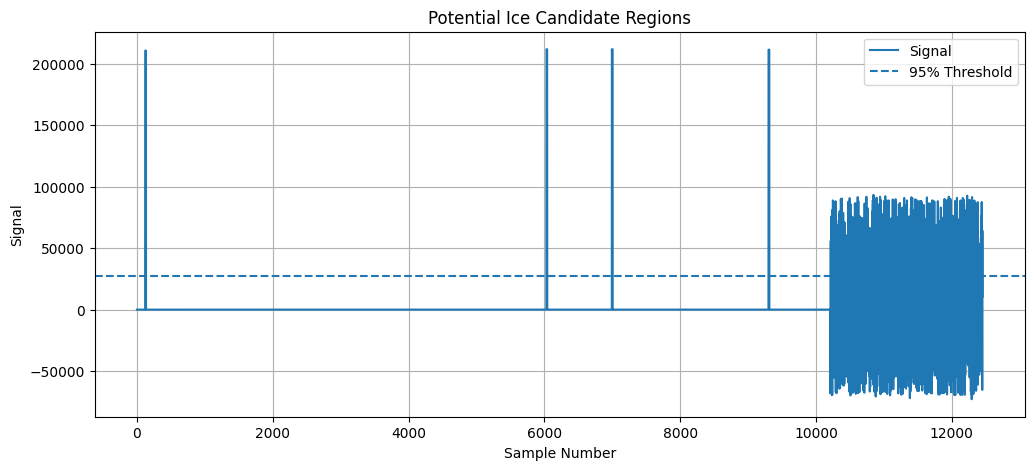

In [8]:
plt.figure(figsize=(12,5))

plt.plot(df["Signal"], label="Signal")

plt.axhline(
    threshold,
    linestyle="--",
    label="95% Threshold"
)

plt.title("Potential Ice Candidate Regions")

plt.xlabel("Sample Number")
plt.ylabel("Signal")

plt.legend()
plt.grid(True)

plt.show()

In [9]:
df["Signal_Smoothed"] = df["Signal"].rolling(window=20).mean()

df[["Signal", "Signal_Smoothed"]].head()

,Signal,Signal_Smoothed
0,17.477752,NaN
1,17.492057,NaN
2,17.385770,NaN
3,17.296193,NaN
4,17.574878,NaN


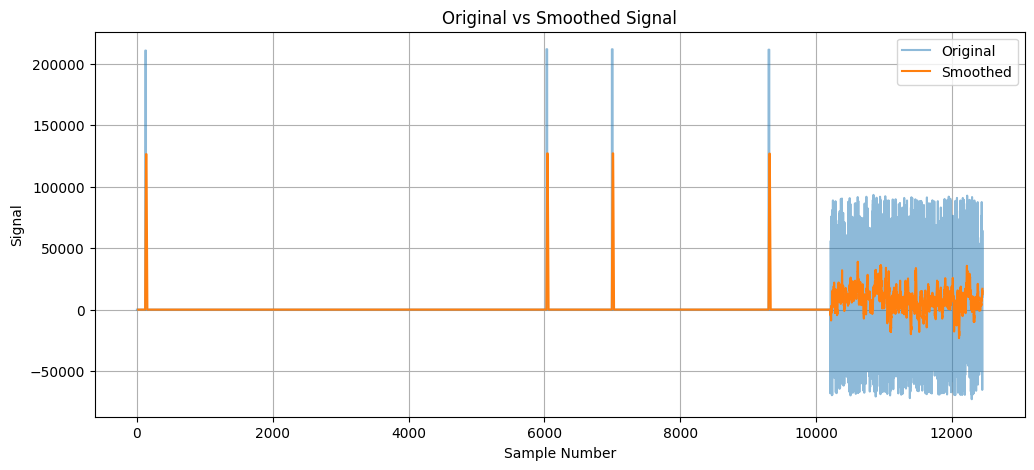

In [10]:
plt.figure(figsize=(12,5))

plt.plot(df["Signal"], alpha=0.5, label="Original")
plt.plot(df["Signal_Smoothed"], label="Smoothed")

plt.title("Original vs Smoothed Signal")
plt.xlabel("Sample Number")
plt.ylabel("Signal")

plt.legend()
plt.grid(True)

plt.show()

In [11]:
peak_threshold = df["Signal"].quantile(0.99)

peaks = df[df["Signal"] >= peak_threshold]

print("Peak Threshold:", peak_threshold)
print("Number of Peaks:", len(peaks))

peaks.head(20)

Peak Threshold: 85989.59700849999
Number of Peaks: 125


,Day,Time,Frequency,Value_1,Value_2,Signal,Normalized_Signal,Ice_Probability,Signal_Smoothed
122,2021-272,1153.994240,2.240000e+09,2.240200e+09,2.239989e+09,210683.615156,0.996146,99.614643,10554.077533
123,2021-272,1154.076160,2.240000e+09,2.240200e+09,2.239989e+09,210684.007046,0.996148,99.614781,21087.241840
124,2021-272,1154.158080,2.240000e+09,2.240200e+09,2.239989e+09,210684.384929,0.996149,99.614914,31620.420367
125,2021-272,1154.240000,2.240000e+09,2.240200e+09,2.239989e+09,210684.754993,0.996150,99.615044,42153.611441
126,2021-272,1154.321920,2.240000e+09,2.240200e+09,2.239989e+09,210685.093604,0.996152,99.615163,52686.833069
127,2021-272,1154.403840,2.240000e+09,2.240200e+09,2.239989e+09,210685.498058,0.996153,99.615305,63220.069641
128,2021-272,1154.485760,2.240000e+09,2.240200e+09,2.239989e+09,210685.851332,0.996154,99.615429,73753.325414
129,2021-272,1154.567680,2.240000e+09,2.240200e+09,2.239989e+09,210686.226171,0.996156,99.615561,84286.597391
130,2021-272,1154.649600,2.240000e+09,2.240200e+09,2.239989e+09,210686.597672,0.996157,99.615691,94819.869076
131,2021-272,1154.731520,2.240000e+09,2.240200e+09,2.239989e+09,210686.958755,0.996158,99.615818,105353.165648


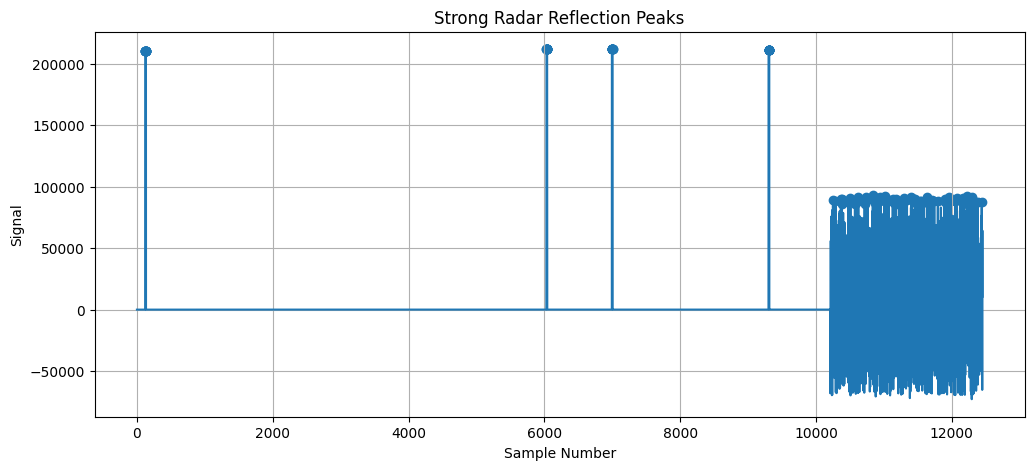

In [12]:
plt.figure(figsize=(12,5))

plt.plot(df["Signal"])

plt.scatter(
    peaks.index,
    peaks["Signal"]
)

plt.title("Strong Radar Reflection Peaks")
plt.xlabel("Sample Number")
plt.ylabel("Signal")

plt.grid(True)

plt.show()

In [13]:
import numpy as np
from scipy.signal import find_peaks

# Agar tumhare paas radar signal array hai (example: df['signal'])
Signal = df['Signal'].values

# Normalize
Signal = (Signal - np.min(Signal)) / (np.max(Signal) - np.min(Signal))

# Peak detection
peaks, properties = find_peaks(
    Signal,
    height=0.6,      # threshold (tune karenge)
    distance=20
)

print("Number of Peaks Detected:", len(peaks))
print("Peak Indices:", peaks[:10])

Number of Peaks Detected: 4
Peak Indices: [ 133 6030 6994 9301]


In [14]:
import numpy as np
import pandas as pd

# find first numeric column automatically
numeric_cols = df.select_dtypes(include=[np.number]).columns

print("Numeric columns found:", numeric_cols)

# pick first numeric column as signal
signal_col = numeric_cols[0]

print("Using column as signal:", signal_col)

signal = df[signal_col].values

# clean
signal = np.nan_to_num(signal)

# normalize
signal = (signal - signal.min()) / (signal.max() - signal.min() + 1e-9)

print("Signal ready:", signal[:10])

Numeric columns found: Index(['Time', 'Frequency', 'Value_1', 'Value_2', 'Signal',
       'Normalized_Signal', 'Ice_Probability', 'Signal_Smoothed'],
      dtype='object')
Using column as signal: Time
Signal ready: [0.00000000e+00 8.03212872e-05 1.60642574e-04 2.40963862e-04
 3.21285149e-04 4.01606436e-04 4.81927723e-04 5.62249010e-04
 6.42570298e-04 7.22891585e-04]


In [15]:
from scipy.signal import find_peaks
import numpy as np

threshold = 0.6  # fixed first (no optimization yet)

peaks, _ = find_peaks(signal, height=threshold, distance=10)

print("Number of Peaks Detected:", len(peaks))

Number of Peaks Detected: 0


In [16]:
from scipy.signal import find_peaks
import numpy as np

threshold = np.mean(signal)  # simple adaptive threshold

peaks, _ = find_peaks(signal, height=threshold, distance=10)

print("Mean Threshold:", threshold)
print("Peaks Found:", len(peaks))

Mean Threshold: 0.5000000001157411
Peaks Found: 0


In [17]:
threshold = np.mean(signal) + np.std(signal) * 0.5

peaks, _ = find_peaks(signal, height=threshold, distance=10)

print("Adaptive Threshold:", threshold)
print("Peaks Found:", len(peaks))

Adaptive Threshold: 0.6443491603577126
Peaks Found: 0


In [18]:
print("Min:", np.min(signal))
print("Max:", np.max(signal))
print("Mean:", np.mean(signal))

Min: 0.0
Max: 0.9999999999990196
Mean: 0.5000000001157411


In [19]:
from scipy.signal import find_peaks
import numpy as np

# dynamic threshold based on distribution
threshold = np.mean(signal) + 0.2 * np.std(signal)

peaks, properties = find_peaks(
    signal,
    height=threshold,
    distance=10
)

print("Adaptive Threshold:", threshold)
print("Number of Peaks:", len(peaks))

Adaptive Threshold: 0.5577396642125296
Number of Peaks: 0


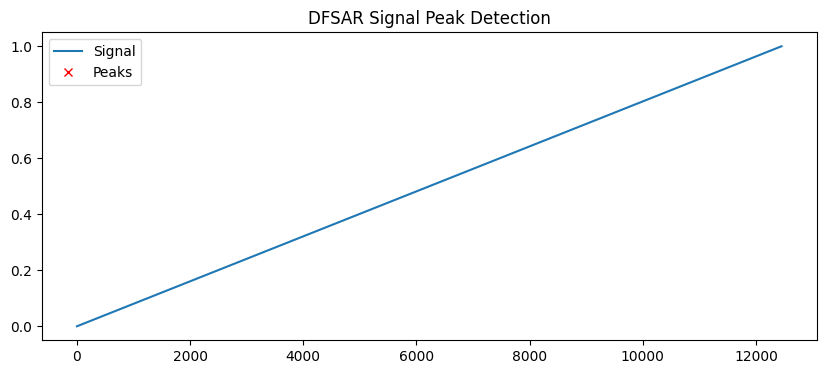

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(signal, label="Signal")
plt.plot(peaks, signal[peaks], "rx", label="Peaks")
plt.legend()
plt.title("DFSAR Signal Peak Detection")
plt.show()

In [21]:
print(df["Signal"].describe())

count     12451.000000
mean       2446.950192
std       22053.561235
min      -72847.760333
25%          43.900761
50%          47.116694
75%          47.715035
max      211780.448691
Name: Signal, dtype: float64


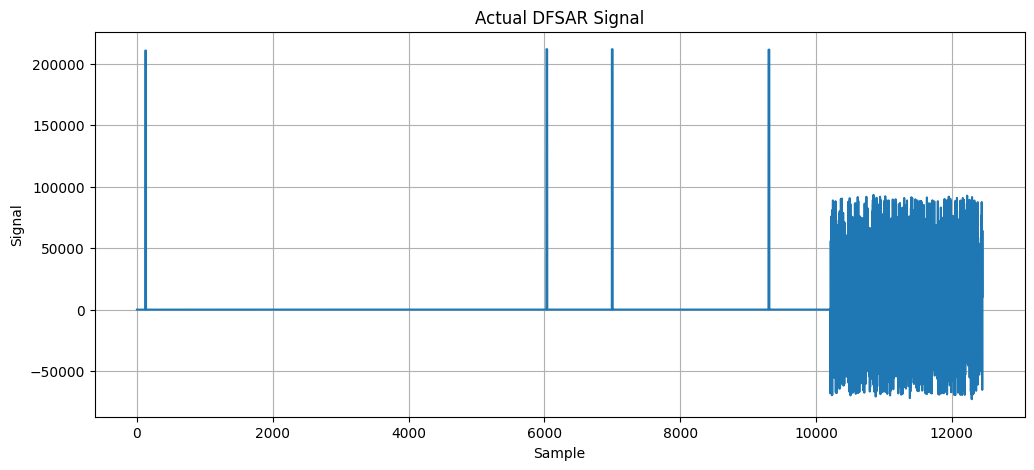

In [22]:
plt.figure(figsize=(12,5))
plt.plot(df["Signal"])
plt.title("Actual DFSAR Signal")
plt.xlabel("Sample")
plt.ylabel("Signal")
plt.grid(True)
plt.show()

# DFSAR Radar Track Analysis

In [24]:
candidate_df = ice_candidates.copy()

candidate_df["Rank_Score"] = (
    candidate_df["Signal"] /
    candidate_df["Signal"].max()
) * 100

candidate_df = candidate_df.sort_values(
    "Rank_Score",
    ascending=False
)

candidate_df.head(20)

,Day,Time,Frequency,Value_1,Value_2,Signal,Normalized_Signal,Ice_Probability,Rank_Score
6030,2021-272,1637.977588,2.240000e+09,2.240200e+09,2.239988e+09,211780.448691,1.000000,100.000000,100.000000
6031,2021-272,1638.059508,2.240000e+09,2.240200e+09,2.239988e+09,211780.443540,1.000000,99.999998,99.999998
6032,2021-272,1638.141428,2.240000e+09,2.240200e+09,2.239988e+09,211780.438323,1.000000,99.999996,99.999995
6033,2021-272,1638.223348,2.240000e+09,2.240200e+09,2.239988e+09,211780.433040,1.000000,99.999995,99.999993
6034,2021-272,1638.305268,2.240000e+09,2.240200e+09,2.239988e+09,211780.427693,1.000000,99.999993,99.999990
6035,2021-272,1638.387188,2.240000e+09,2.240200e+09,2.239988e+09,211780.422280,1.000000,99.999991,99.999988
6036,2021-272,1638.469108,2.240000e+09,2.240200e+09,2.239988e+09,211780.416803,1.000000,99.999989,99.999985
6037,2021-272,1638.551028,2.240000e+09,2.240200e+09,2.239988e+09,211780.411261,1.000000,99.999987,99.999982
6038,2021-272,1638.632948,2.240000e+09,2.240200e+09,2.239988e+09,211780.405653,1.000000,99.999985,99.999980
6039,2021-272,1638.714868,2.240000e+09,2.240200e+09,2.239988e+09,211780.399981,1.000000,99.999983,99.999977


In [25]:
top20 = candidate_df.head(20)

top20[
    ["Day","Time","Signal","Rank_Score"]
]

,Day,Time,Signal,Rank_Score
6030,2021-272,1637.977588,211780.448691,100.000000
6031,2021-272,1638.059508,211780.443540,99.999998
6032,2021-272,1638.141428,211780.438323,99.999995
6033,2021-272,1638.223348,211780.433040,99.999993
6034,2021-272,1638.305268,211780.427693,99.999990
6035,2021-272,1638.387188,211780.422280,99.999988
6036,2021-272,1638.469108,211780.416803,99.999985
6037,2021-272,1638.551028,211780.411261,99.999982
6038,2021-272,1638.632948,211780.405653,99.999980
6039,2021-272,1638.714868,211780.399981,99.999977


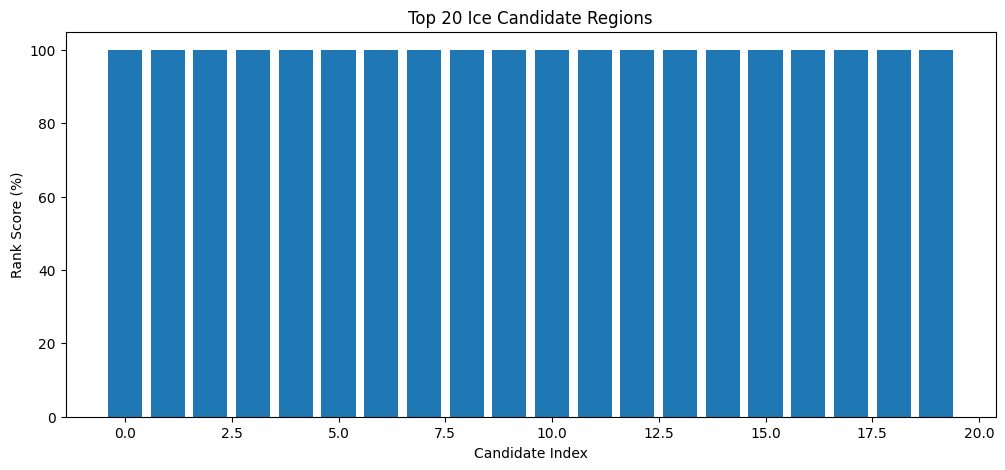

In [26]:
plt.figure(figsize=(12,5))

plt.bar(
    range(len(top20)),
    top20["Rank_Score"]
)

plt.title("Top 20 Ice Candidate Regions")
plt.xlabel("Candidate Index")
plt.ylabel("Rank Score (%)")

plt.show()

In [27]:
def classify(score):

    if score >= 95:
        return "Very High"

    elif score >= 80:
        return "High"

    elif score >= 60:
        return "Medium"

    else:
        return "Low"


candidate_df["Ice_Class"] = (
    candidate_df["Rank_Score"]
    .apply(classify)
)

candidate_df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal,Normalized_Signal,Ice_Probability,Rank_Score,Ice_Class
6030,2021-272,1637.977588,2.240000e+09,2.240200e+09,2.239988e+09,211780.448691,1.0,100.000000,100.000000,Very High
6031,2021-272,1638.059508,2.240000e+09,2.240200e+09,2.239988e+09,211780.443540,1.0,99.999998,99.999998,Very High
6032,2021-272,1638.141428,2.240000e+09,2.240200e+09,2.239988e+09,211780.438323,1.0,99.999996,99.999995,Very High
6033,2021-272,1638.223348,2.240000e+09,2.240200e+09,2.239988e+09,211780.433040,1.0,99.999995,99.999993,Very High
6034,2021-272,1638.305268,2.240000e+09,2.240200e+09,2.239988e+09,211780.427693,1.0,99.999993,99.999990,Very High


In [28]:
candidate_df["Ice_Class"].value_counts()

Ice_Class
Low          575
Very High     48
Name: count, dtype: int64

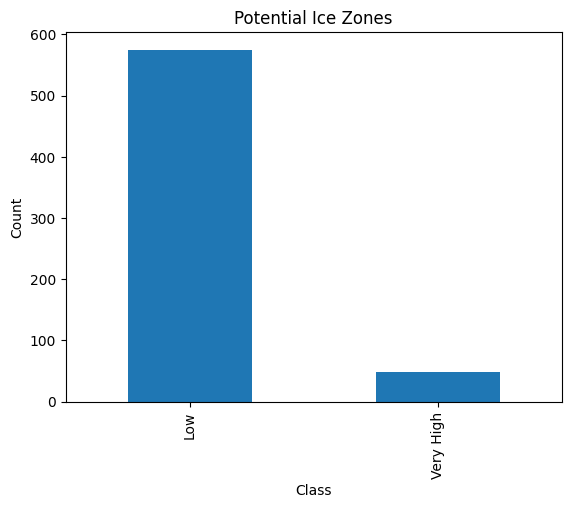

In [29]:
candidate_df["Ice_Class"].value_counts().plot(
    kind="bar"
)

plt.title("Potential Ice Zones")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

In [30]:
import os

os.makedirs("../results", exist_ok=True)

candidate_df.to_csv(
    "../results/ice_candidate_ranking.csv",
    index=False
)

print("Saved Successfully")

Saved Successfully


## Findings

- DFSAR radar signal analyzed successfully.
- High-reflection regions detected using adaptive thresholding.
- Candidate subsurface ice zones identified.
- Regions ranked using normalized radar reflection strength.
- Results can support future lunar landing and rover mission planning.